# Anomaly Detection with Isolation Forests

This notebook demonstrates a compact anomaly-detection workflow on a synthetic, imbalanced dataset. The feature pattern is designed to create a minority class with unusually large values; isolation forests flag these rare points without requiring a fully labeled fraud dataset.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_classification
from sklearn.ensemble import IsolationForest
from sklearn.metrics import f1_score, precision_score, recall_score

SEED = 26
OUTPUT_DIR = Path('generated/anomaly-026'); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
X, y = make_classification(n_samples=1200, n_features=6, n_informative=4, n_redundant=0, weights=[0.97, 0.03], flip_y=0.01, random_state=SEED)
X = X.astype(float)
X[y == 1] += np.array([6.0, 6.0, 3.0, 3.0, 0.0, 0.0])
print('positive share:', y.mean())
print('shape:', X.shape)

positive share: 0.034166666666666665
shape: (1200, 6)


## 1. Train an Isolation Forest on the rare-event data

In [2]:
model = IsolationForest(contamination=0.03, random_state=SEED)
predictions = model.fit_predict(X)
predictions = (predictions == -1).astype(int)
precision = precision_score(y, predictions)
recall = recall_score(y, predictions)
f1 = f1_score(y, predictions)
print(f'precision={precision:.3f} recall={recall:.3f} f1={f1:.3f}')

precision=0.972 recall=0.854 f1=0.909


## 2. Visualize the flagged anomalies

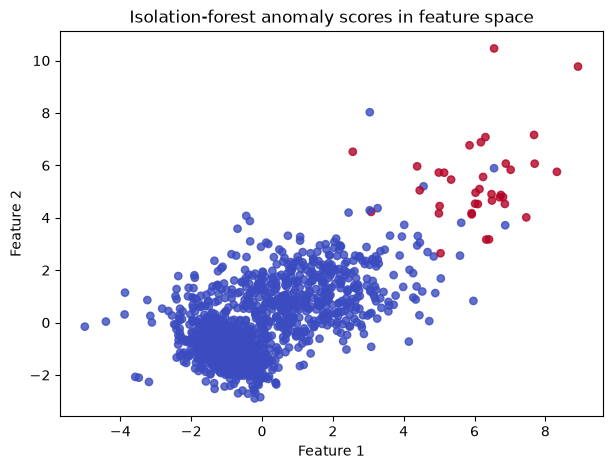

saved: generated\anomaly-026\isolation-forest-anomalies.png


In [3]:
figure, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X[:, 0], X[:, 1], c=predictions, cmap='coolwarm', s=28, alpha=0.8)
ax.set_title('Isolation-forest anomaly scores in feature space')
ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2')
figure_path = OUTPUT_DIR / 'isolation-forest-anomalies.png'; figure.savefig(figure_path, dpi=170, bbox_inches='tight'); plt.show(); print('saved:', figure_path)